# 9. Comparación de resultados

Este capítulo reúne en una sola vista lo medido en los capítulos 4 a 8: calidad por entorno, modelo y codificación, y su costo.

In [1]:
import sys, json
sys.path.insert(0, "../src")
import numpy as np, pandas as pd, matplotlib.pyplot as plt
from ctr.plots import C, style, es
from ctr.config import RES
from ctr.monitor import read_jsonl
from ctr.metrics import t_ci
style()
pd.set_option("display.max_columns", 30)
R = pd.DataFrame(read_jsonl(RES / "sk" / "runs.jsonl")); S = pd.DataFrame(read_jsonl(RES / "spark" / "runs.jsonl"))
S = S[S.status == "ok"]

## 9.1 Por entorno, modelo y codificación

Validación, día 29, con 1 millón de filas o el tamaño indicado. Media, desviación e intervalo t al 95 % cuando hay varias semillas.

In [2]:
def fila(env, mod, enc, g, col="v_auc"):
    m, s, lo, hi = t_ci(g[col].values)
    return {"Entorno": env, "Modelo": mod, "Codificación": enc, "n": int(g.n.iloc[0]), "Semillas": len(g), "AUC": m, "Desv.": s, "IC bajo": lo, "IC alto": hi,
            "Log loss": g.v_logloss.mean(), "ECE": g.v_ece.mean(), "Ajuste (s)": g.fit_sec.mean(), "GB pico": g.gb.mean()}
filas = []
e = R[R.exp == "enc"]
for (m, c), g in e.groupby(["model", "enc"]):
    filas.append(fila("scikit-learn", m.upper(), c, g))
s = R[R.exp == "scale"]
for (m, c, n), g in s[s.n > 5e6].groupby(["model", "enc", "n"]):
    filas.append(fila("scikit-learn", m.upper(), c, g))
sp = S[S.exp.isin(["scale", "full"])].copy()
sp["cap"] = sp.layers.map(lambda l: "x".join(map(str, l)))
for (m, c, ca, n, mi), g in sp.groupby(["model", "enc", "cap", "n", "maxIter"]):
    filas.append(fila("PySpark", (m + " " + ca).upper().strip(), c, g))
T = pd.DataFrame(filas).sort_values("AUC", ascending=False).round(4).reset_index(drop=True)
T

,Entorno,Modelo,Codificación,n,Semillas,AUC,Desv.,IC bajo,IC alto,Log loss,ECE,Ajuste (s),GB pico
0,scikit-learn,HGB,target,10000000,5,0.7425,0.0004,0.7420,0.7430,0.3822,0.0132,765.2784,3.6832
1,scikit-learn,MLP,hash16,1000000,5,0.7400,0.0009,0.7390,0.7411,0.3848,0.0184,2198.3239,0.6925
2,scikit-learn,MLP,hash12,10000000,5,0.7390,0.0017,0.7369,0.7411,0.3877,0.0313,2093.8492,4.3030
3,scikit-learn,HGB,target,1000000,5,0.7390,0.0006,0.7382,0.7397,0.3839,0.0081,71.7215,0.4197
4,scikit-learn,MLP,hash14,1000000,5,0.7390,0.0018,0.7367,0.7412,0.3854,0.0168,659.8008,0.5960
5,scikit-learn,MLP,hash12,1000000,5,0.7382,0.0017,0.7360,0.7403,0.3855,0.0152,187.5408,0.5727
6,scikit-learn,HGB,freq,1000000,5,0.7330,0.0012,0.7315,0.7346,0.3868,0.0107,72.5181,0.4327
7,PySpark,LR,hash12,32377421,1,0.7305,0.0000,0.7305,0.7305,0.3891,0.0195,177.2492,14.2981
8,PySpark,LR,hash12,999123,1,0.7300,0.0000,0.7300,0.7300,0.3889,0.0149,37.2524,7.2163
9,scikit-learn,MLP,target,1000000,5,0.7299,0.0012,0.7284,0.7314,0.3886,0.0156,60.4194,0.2925


## 9.2 Barras comparativas de tiempo y memoria

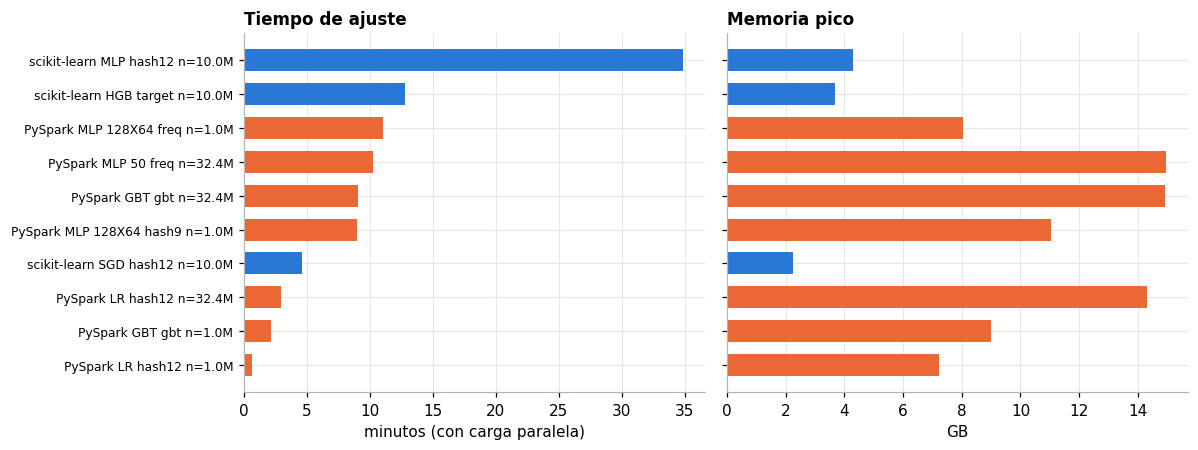

In [3]:
d = T[T.n > 5e5].sort_values("Ajuste (s)")
d = d[d["Entorno"].eq("PySpark") | d.n.gt(5e6)]
fig, ax = plt.subplots(1, 2, figsize=(11, 4.2), sharey=True)
et = d.Entorno + " " + d.Modelo + " " + d["Codificación"] + " n=" + (d.n / 1e6).round(1).astype(str) + "M"
col = [C["azul"] if x == "scikit-learn" else C["naranja"] for x in d.Entorno]
ax[0].barh(et, d["Ajuste (s)"] / 60, color=col, height=.65); ax[0].set(title="Tiempo de ajuste", xlabel="minutos (con carga paralela)")
ax[1].barh(et, d["GB pico"], color=col, height=.65); ax[1].set(title="Memoria pico", xlabel="GB")
ax[0].tick_params(axis="y", labelsize=8); plt.tight_layout(); plt.show()

**Lectura de conjunto:**

- **El orden por calidad no depende del entorno, sino de la representación.** Arriba quedan los modelos que ven la identidad de
  las categorías con muchas filas: HGB con target, MLP y SGD con hashing en scikit-learn, y la LR dispersa de Spark. Abajo queda
  todo lo que usa frecuencia sola.
- **El MLP de Spark está acotado por diseño,** no por falta de ajuste: con hashing no puede usar más de 1 millón de filas, y con
  frecuencia pierde la identidad.
- **El costo crece mucho más rápido que la calidad.** hash16 cuesta 12 veces hash12 por 0,002 de AUC. El MLP con 10 millones cuesta
  13 veces el de 1 millón por 0,001.
- **Los tiempos de esta tabla tienen carga paralela** y sirven solo para comparar órdenes de magnitud. Las mediciones limpias están
  en el capítulo 7.